In [1]:
print("tara")

tara


In [2]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND PROJECT CONFIGURATION
# ============================================================

import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# Reproducibility
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


# ------------------------------------------------------------
# PROJECT PATHS
# ------------------------------------------------------------

DATA_DIR = Path("data")

CACD2000_PATH = (
    DATA_DIR / "CACD2000"
)

VERIFICATION_PATH = (
    DATA_DIR / "CACD_VerificationSet"
)


# ------------------------------------------------------------
# PRINT CONFIGURATION
# ------------------------------------------------------------

print("========== PROJECT CONFIGURATION ==========")

print("\nMain Dataset:")
print(CACD2000_PATH)

print(
    "Exists:",
    CACD2000_PATH.exists()
)

print("\nVerification Dataset:")
print(VERIFICATION_PATH)

print(
    "Exists:",
    VERIFICATION_PATH.exists()
)

print("\nRandom Seed:")
print(RANDOM_SEED)

========== PROJECT CONFIGURATION ==========

Main Dataset:
data/CACD2000
Exists: True

Verification Dataset:
data/CACD_VerificationSet
Exists: True

Random Seed:
42


In [3]:
# ============================================================
# CELL 2: VERIFY MAIN DATASET
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png"
}


image_files = [
    file
    for file in CACD2000_PATH.iterdir()
    if (
        file.is_file()
        and file.suffix.lower()
        in IMAGE_EXTENSIONS
    )
]


print("========== CACD2000 DATASET CHECK ==========")

print(
    "Total images:",
    len(image_files)
)

print(
    "Expected images:",
    156447
)


if len(image_files) == 156447:

    print(
        "\n✓ Dataset image count is correct."
    )

else:

    print(
        "\n⚠ Dataset image count does not match expected value."
    )

========== CACD2000 DATASET CHECK ==========
Total images: 156447
Expected images: 156447

✓ Dataset image count is correct.


In [4]:
# ============================================================
# CELL 3: DISPLAY SAMPLE FILENAMES
# ============================================================

print("========== SAMPLE FILENAMES ==========")

sample_files = sorted(
    image_files
)[:50]


for file in sample_files:

    print(
        file.name
    )


# Random sample

random_sample = random.sample(
    image_files,
    min(20, len(image_files))
)

print("\n========== RANDOM FILENAMES ==========")

for file in random_sample:

    print(
        file.name
    )

========== SAMPLE FILENAMES ==========
0001_Aaron_Ashmore_25_0003.jpg
0001_Aaron_Ashmore_25_0005.jpg
0001_Aaron_Ashmore_25_0011.jpg
0001_Aaron_Ashmore_25_0012.jpg
0001_Aaron_Ashmore_25_0014.jpg
0001_Aaron_Ashmore_25_0015.jpg
0001_Aaron_Ashmore_25_0018.jpg
0001_Aaron_Ashmore_26_0004.jpg
0001_Aaron_Ashmore_26_0009.jpg
0001_Aaron_Ashmore_26_0011.jpg
0001_Aaron_Ashmore_26_0012.jpg
0001_Aaron_Ashmore_26_0014.jpg
0001_Aaron_Ashmore_27_0001.jpg
0001_Aaron_Ashmore_27_0003.jpg
0001_Aaron_Ashmore_27_0004.jpg
0001_Aaron_Ashmore_27_0005.jpg
0001_Aaron_Ashmore_27_0008.jpg
0001_Aaron_Ashmore_27_0012.jpg
0001_Aaron_Ashmore_28_0002.jpg
0001_Aaron_Ashmore_28_0003.jpg
0001_Aaron_Ashmore_28_0016.jpg
0001_Aaron_Ashmore_29_0002.jpg
0001_Aaron_Ashmore_29_0010.jpg
0001_Aaron_Ashmore_29_0014.jpg
0001_Aaron_Ashmore_29_0015.jpg
0001_Aaron_Ashmore_30_0002.jpg
0001_Aaron_Ashmore_30_0003.jpg
0001_Aaron_Ashmore_30_0005.jpg
0001_Aaron_Ashmore_30_0007.jpg
0001_Aaron_Ashmore_30_0009.jpg
0001_Aaron_Ashmore_30_0012.jpg


In [5]:
# ============================================================
# CELL 4: CREATE METADATA FROM RENAMED CACD2000 FILENAMES
# ============================================================

# Example filename:
# 0001_Aaron_Ashmore_25_0003.jpg

pattern = re.compile(
    r"^(\d+)_(.+)_(\d+)_(\d+)\.(jpg|jpeg|png)$",
    re.IGNORECASE
)

records = []

for file_path in CACD2000_PATH.iterdir():

    if not file_path.is_file():
        continue

    match = pattern.match(file_path.name)

    if match:

        sr_no = int(match.group(1))
        full_name = match.group(2)
        age = int(match.group(3))
        image_no = int(match.group(4))

        records.append({
            "sr_no": sr_no,
            "name": full_name,
            "age": age,
            "image_no": image_no,
            "filename": file_path.name,
            "filepath": str(file_path)
        })


df = pd.DataFrame(records)

print("========== METADATA CREATED ==========")

print(
    "Total images:",
    len(df)
)

print(
    "Unique celebrities:",
    df["name"].nunique()
)

print(
    "Minimum age:",
    df["age"].min()
)

print(
    "Maximum age:",
    df["age"].max()
)

print("======================================")

display(df.head(10))

========== METADATA CREATED ==========
Total images: 156447
Unique celebrities: 1906
Minimum age: 14
Maximum age: 62


,sr_no,name,age,image_no,filename,filepath
0,1349,Miko_Hughes,27,2,1349_Miko_Hughes_27_0002.jpg,data/CACD2000/1349_Miko_Hughes_27_0002.jpg
1,248,Candice_Accola,23,1,0248_Candice_Accola_23_0001.jpg,data/CACD2000/0248_Candice_Accola_23_0001.jpg
2,723,Jake_Thomas,23,10,0723_Jake_Thomas_23_0010.jpg,data/CACD2000/0723_Jake_Thomas_23_0010.jpg
3,461,Diablo_Cody,27,16,0461_Diablo_Cody_27_0016.jpg,data/CACD2000/0461_Diablo_Cody_27_0016.jpg
4,766,Jason_Alexander,49,4,0766_Jason_Alexander_49_0004.jpg,data/CACD2000/0766_Jason_Alexander_49_0004.jpg
5,909,Jonathan_Lipnicki,14,2,0909_Jonathan_Lipnicki_14_0002.jpg,data/CACD2000/0909_Jonathan_Lipnicki_14_0002.jpg
6,698,Irina_Shayk,23,9,0698_Irina_Shayk_23_0009.jpg,data/CACD2000/0698_Irina_Shayk_23_0009.jpg
7,1605,Russell_Crowe,41,11,1605_Russell_Crowe_41_0011.jpg,data/CACD2000/1605_Russell_Crowe_41_0011.jpg
8,504,Edward_Furlong,33,1,0504_Edward_Furlong_33_0001.jpg,data/CACD2000/0504_Edward_Furlong_33_0001.jpg
9,1446,Parker_Posey,44,7,1446_Parker_Posey_44_0007.jpg,data/CACD2000/1446_Parker_Posey_44_0007.jpg


In [6]:
# ============================================================
# CELL 5: DATASET INTEGRITY CHECK
# ============================================================

print("========== DATASET INTEGRITY CHECK ==========")

# ------------------------------------------------------------
# 1. Missing Values
# ------------------------------------------------------------

print("\nMissing values:")

print(
    df.isnull().sum()
)


# ------------------------------------------------------------
# 2. Duplicate Records
# ------------------------------------------------------------

print("\nDuplicate records:")

print(
    df.duplicated().sum()
)


# ------------------------------------------------------------
# 3. Duplicate Filenames
# ------------------------------------------------------------

print("\nDuplicate filenames:")

print(
    df["filename"].duplicated().sum()
)


# ------------------------------------------------------------
# 4. Number of Images Per Celebrity
# ------------------------------------------------------------

images_per_person = (
    df.groupby("name")
      .size()
)

print("\nImages per celebrity:")

print(
    images_per_person.describe()
)


# ------------------------------------------------------------
# 5. Check File Existence
# ------------------------------------------------------------

missing_files = df[
    ~df["filepath"].apply(
        lambda x: Path(x).exists()
    )
]

print("\nMissing physical files:")

print(
    len(missing_files)
)


# ------------------------------------------------------------
# FINAL RESULT
# ------------------------------------------------------------

print("\n========== INTEGRITY RESULT ==========")

if (
    df.isnull().sum().sum() == 0
    and df.duplicated().sum() == 0
    and df["filename"].duplicated().sum() == 0
    and len(missing_files) == 0
):

    print(
        "✓ Dataset integrity check PASSED."
    )

else:

    print(
        "⚠ Dataset integrity check found issues."
    )

========== DATASET INTEGRITY CHECK ==========

Missing values:
sr_no       0
name        0
age         0
image_no    0
filename    0
filepath    0
dtype: int64

Duplicate records:
0

Duplicate filenames:
0

Images per celebrity:
count    1906.000000
mean       82.081322
std        19.547350
min        25.000000
25%        69.000000
50%        81.500000
75%        96.000000
max       139.000000
dtype: float64

Missing physical files:
0

========== INTEGRITY RESULT ==========
✓ Dataset integrity check PASSED.


In [7]:
# ============================================================
# CELL 6: CELEBRITY CROSS-AGE ANALYSIS
# ============================================================

celebrity_summary = (
    df.groupby(
        ["sr_no", "name"]
    )
    .agg(
        min_age=("age", "min"),
        max_age=("age", "max"),
        total_images=("filename", "count"),
        unique_ages=("age", "nunique")
    )
    .reset_index()
)


# ------------------------------------------------------------
# CALCULATE AGE GAP
# ------------------------------------------------------------

celebrity_summary["age_gap"] = (
    celebrity_summary["max_age"]
    - celebrity_summary["min_age"]
)


# ------------------------------------------------------------
# SORT BY AGE GAP
# ------------------------------------------------------------

celebrity_summary = (
    celebrity_summary
    .sort_values(
        by=[
            "age_gap",
            "total_images"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# DISPLAY SUMMARY
# ------------------------------------------------------------

print(
    "========== CELEBRITY CROSS-AGE ANALYSIS =========="
)

print(
    "\nTotal celebrities:",
    len(celebrity_summary)
)

print(
    "Minimum age gap:",
    celebrity_summary["age_gap"].min()
)

print(
    "Maximum age gap:",
    celebrity_summary["age_gap"].max()
)

print(
    "Average age gap:",
    round(
        celebrity_summary["age_gap"].mean(),
        2
    )
)


# ------------------------------------------------------------
# CELEBRITIES WITH >= 5 YEARS AGE GAP
# ------------------------------------------------------------

eligible_5_year = (
    celebrity_summary[
        celebrity_summary["age_gap"] >= 5
    ]
)

print(
    "\nCelebrities with age gap >= 5 years:",
    len(eligible_5_year)
)

print(
    "Percentage:",
    round(
        len(eligible_5_year)
        / len(celebrity_summary)
        * 100,
        2
    ),
    "%"
)


# ------------------------------------------------------------
# DISPLAY TOP RESULTS
# ------------------------------------------------------------

print(
    "\n========== TOP 20 CELEBRITIES =========="
)

display(
    celebrity_summary.head(20)
)

========== CELEBRITY CROSS-AGE ANALYSIS ==========

Total celebrities: 1906
Minimum age gap: 7
Maximum age gap: 9
Average age gap: 8.99

Celebrities with age gap >= 5 years: 1906
Percentage: 100.0 %

========== TOP 20 CELEBRITIES ==========


,sr_no,name,min_age,max_age,total_images,unique_ages,age_gap
0,549,Emma_Stone,16,25,139,10,9
1,551,Emma_Watson,14,23,134,10,9
2,1566,Robert_Pattinson,18,27,134,10,9
3,123,Anne_Hathaway,22,31,133,10,9
4,1193,Maggie_Gyllenhaal,27,36,133,10,9
5,390,Daniel_Craig,36,45,132,10,9
6,244,Cameron_Diaz,32,41,130,10,9
7,1625,Sandra_Bullock,40,49,130,10,9
8,109,Angelina_Jolie,29,38,129,10,9
9,32,Alec_Baldwin,46,55,128,10,9


========== AGE DISTRIBUTION ==========

Age statistics:
count    156447.000000
mean         37.963195
std          11.716546
min          14.000000
25%          28.000000
50%          38.000000
75%          48.000000
max          62.000000
Name: age, dtype: float64

Images available for each age:
age
14     249
15     584
16     948
17    1239
18    1608
19    2008
20    2485
21    2961
22    3540
23    3933
24    4121
25    4159
26    4103
27    4137
28    4204
29    4280
30    4176
31    4207
32    4111
33    4211
34    4190
35    4198
36    4171
37    4182
38    4021
39    4051
40    4107
41    4051
42    3871
43    3821
44    3902
45    3688
46    3698
47    3628
48    3721
49    3653
50    3661
51    3611
52    3552
53    3469
54    3213
55    3000
56    2671
57    2405
58    2075
59    1759
60    1301
61     997
62     516
Name: count, dtype: int64


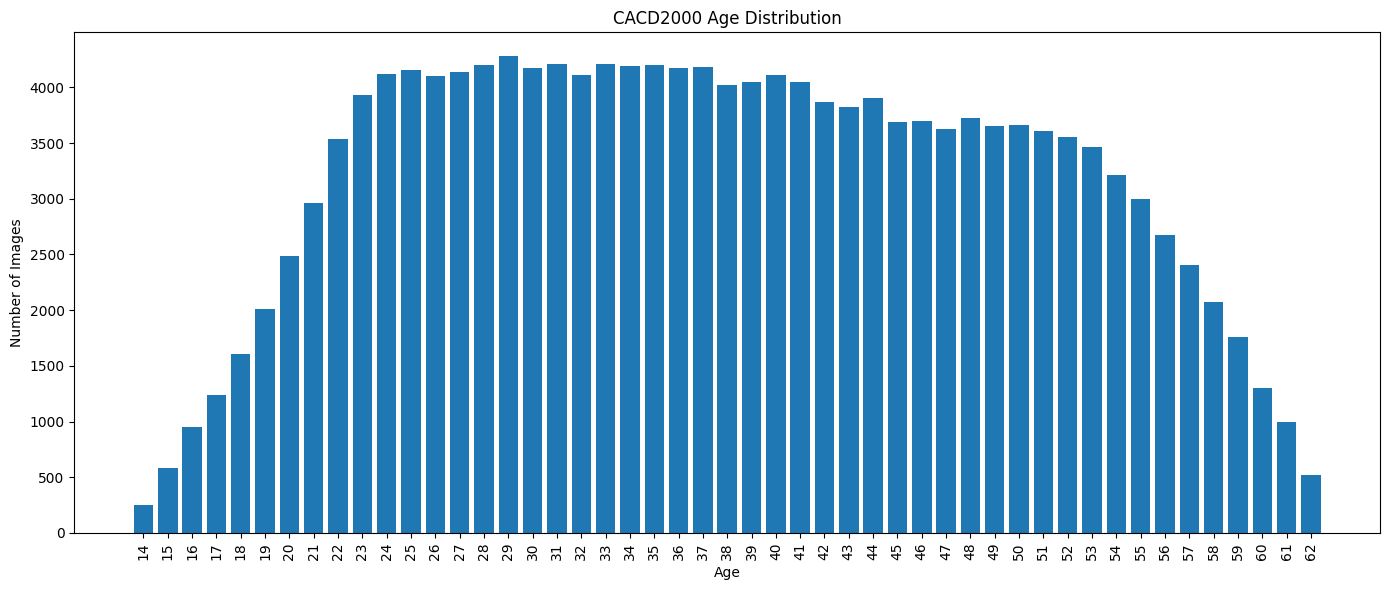

In [8]:
# ============================================================
# CELL 7: AGE DISTRIBUTION ANALYSIS
# ============================================================

age_distribution = (
    df["age"]
    .value_counts()
    .sort_index()
)

print("========== AGE DISTRIBUTION ==========")

print("\nAge statistics:")
print(
    df["age"].describe()
)

print("\nImages available for each age:")
print(
    age_distribution
)


# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.bar(
    age_distribution.index,
    age_distribution.values
)

plt.xlabel("Age")
plt.ylabel("Number of Images")
plt.title("CACD2000 Age Distribution")

plt.xticks(
    age_distribution.index,
    rotation=90
)

plt.tight_layout()

plt.show()

========== IMAGES PER CELEBRITY ==========
count    1906.000000
mean       82.081322
std        19.547350
min        25.000000
25%        69.000000
50%        81.500000
75%        96.000000
max       139.000000
Name: total_images, dtype: float64

Top 20 celebrities with most images:


,sr_no,name,total_images
548,549,Emma_Stone,139
1565,1566,Robert_Pattinson,134
550,551,Emma_Watson,134
1192,1193,Maggie_Gyllenhaal,133
122,123,Anne_Hathaway,133
389,390,Daniel_Craig,132
1624,1625,Sandra_Bullock,130
243,244,Cameron_Diaz,130
108,109,Angelina_Jolie,129
31,32,Alec_Baldwin,128


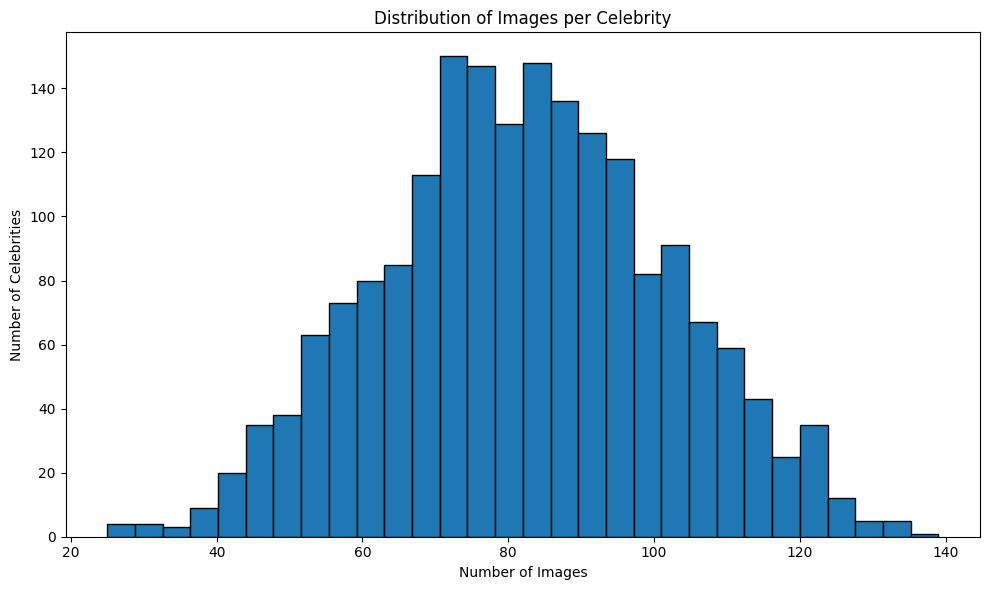

In [9]:
# ============================================================
# CELL 8: IMAGES PER CELEBRITY ANALYSIS
# ============================================================

images_per_celebrity = (
    df.groupby(
        ["sr_no", "name"]
    )
    .size()
    .reset_index(
        name="total_images"
    )
)

print("========== IMAGES PER CELEBRITY ==========")

print(
    images_per_celebrity["total_images"].describe()
)


print("\nTop 20 celebrities with most images:")

display(
    images_per_celebrity
    .sort_values(
        by="total_images",
        ascending=False
    )
    .head(20)
)


# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.hist(
    images_per_celebrity["total_images"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Number of Images")
plt.ylabel("Number of Celebrities")
plt.title("Distribution of Images per Celebrity")

plt.tight_layout()

plt.show()

========== AGE GAP ANALYSIS ==========
count    1906.000000
mean        8.990556
std         0.111844
min         7.000000
25%         9.000000
50%         9.000000
75%         9.000000
max         9.000000
Name: age_gap, dtype: float64

Celebrities for each age gap:
age_gap
7       3
8      12
9    1891
Name: count, dtype: int64


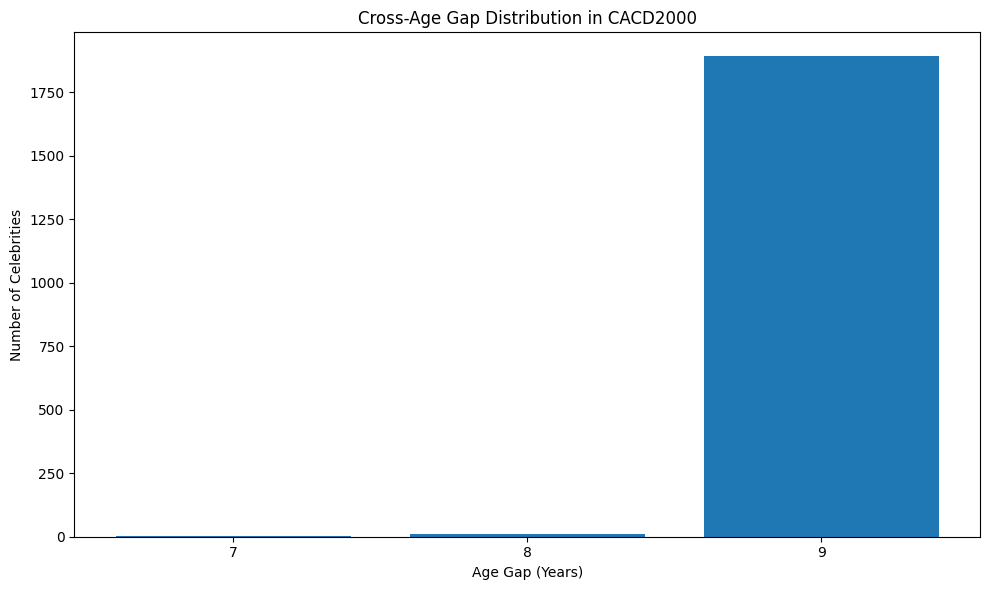

In [10]:
# ============================================================
# CELL 9: AGE GAP DISTRIBUTION
# ============================================================

print("========== AGE GAP ANALYSIS ==========")

print(
    celebrity_summary[
        "age_gap"
    ].describe()
)


age_gap_distribution = (
    celebrity_summary[
        "age_gap"
    ]
    .value_counts()
    .sort_index()
)

print("\nCelebrities for each age gap:")

print(
    age_gap_distribution
)


# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    age_gap_distribution.index,
    age_gap_distribution.values
)

plt.xlabel("Age Gap (Years)")
plt.ylabel("Number of Celebrities")
plt.title("Cross-Age Gap Distribution in CACD2000")

plt.xticks(
    age_gap_distribution.index
)

plt.tight_layout()

plt.show()

In [11]:
# ============================================================
# CELL 10: CHECK 5-YEAR AGE GAP CONDITION
# ============================================================

required_age_gap = 5

eligible_celebrities = (
    celebrity_summary[
        celebrity_summary["age_gap"]
        >= required_age_gap
    ]
)

print("========== 5-YEAR AGE GAP CHECK ==========")

print(
    "Required age gap:",
    required_age_gap,
    "years"
)

print(
    "Total celebrities:",
    len(celebrity_summary)
)

print(
    "Eligible celebrities:",
    len(eligible_celebrities)
)

print(
    "Ineligible celebrities:",
    len(celebrity_summary)
    - len(eligible_celebrities)
)

print(
    "\nPercentage eligible:",
    round(
        len(eligible_celebrities)
        / len(celebrity_summary)
        * 100,
        2
    ),
    "%"
)


print("\nMinimum observed age gap:")

print(
    celebrity_summary[
        "age_gap"
    ].min()
)

========== 5-YEAR AGE GAP CHECK ==========
Required age gap: 5 years
Total celebrities: 1906
Eligible celebrities: 1906
Ineligible celebrities: 0

Percentage eligible: 100.0 %

Minimum observed age gap:
7


In [12]:
# ============================================================
# CELL 11: FINAL MAIN DATASET SUMMARY
# ============================================================

print("=" * 55)
print("       CACD2000 FINAL DATASET SUMMARY")
print("=" * 55)

print(
    "\nTotal Images:",
    len(df)
)

print(
    "Total Celebrities:",
    df["name"].nunique()
)

print(
    "Minimum Age:",
    df["age"].min()
)

print(
    "Maximum Age:",
    df["age"].max()
)

print(
    "Average Age:",
    round(
        df["age"].mean(),
        2
    )
)

print(
    "\nMinimum Images per Celebrity:",
    int(
        images_per_celebrity[
            "total_images"
        ].min()
    )
)

print(
    "Maximum Images per Celebrity:",
    int(
        images_per_celebrity[
            "total_images"
        ].max()
    )
)

print(
    "Average Images per Celebrity:",
    round(
        images_per_celebrity[
            "total_images"
        ].mean(),
        2
    )
)

print(
    "\nMinimum Age Gap:",
    celebrity_summary[
        "age_gap"
    ].min()
)

print(
    "Maximum Age Gap:",
    celebrity_summary[
        "age_gap"
    ].max()
)

print(
    "Average Age Gap:",
    round(
        celebrity_summary[
            "age_gap"
        ].mean(),
        2
    )
)

print(
    "\nCelebrities satisfying >= 5-year gap:",
    len(eligible_celebrities)
)

print("=" * 55)

       CACD2000 FINAL DATASET SUMMARY

Total Images: 156447
Total Celebrities: 1906
Minimum Age: 14
Maximum Age: 62
Average Age: 37.96

Minimum Images per Celebrity: 25
Maximum Images per Celebrity: 139
Average Images per Celebrity: 82.08

Minimum Age Gap: 7
Maximum Age Gap: 9
Average Age Gap: 8.99

Celebrities satisfying >= 5-year gap: 1906


In [13]:
# ============================================================
# CELL 12: SAVE DATASET METADATA
# ============================================================

METADATA_DIR = Path(
    "metadata"
)

METADATA_DIR.mkdir(
    exist_ok=True
)


metadata_path = (
    METADATA_DIR
    / "cacd2000_metadata.csv"
)


df.to_csv(
    metadata_path,
    index=False
)


celebrity_summary_path = (
    METADATA_DIR
    / "celebrity_summary.csv"
)


celebrity_summary.to_csv(
    celebrity_summary_path,
    index=False
)


print("========== METADATA SAVED ==========")

print(
    "Main metadata:"
)

print(
    metadata_path
)

print(
    "\nCelebrity summary:"
)

print(
    celebrity_summary_path
)

print(
    "\nMetadata files saved successfully."
)

========== METADATA SAVED ==========
Main metadata:
metadata/cacd2000_metadata.csv

Celebrity summary:
metadata/celebrity_summary.csv

Metadata files saved successfully.


In [14]:
# ============================================================
# CELL 13: DATA PREPARATION PHASE COMPLETION
# ============================================================

print("========== DATA PREPARATION COMPLETED ==========")

print(
    "\n✓ Dataset paths configured"
)

print(
    "✓ Main dataset verified"
)

print(
    "✓ Filename format checked"
)

print(
    "✓ Metadata created"
)

print(
    "✓ Dataset integrity verified"
)

print(
    "✓ Celebrity cross-age analysis completed"
)

print(
    "✓ Age distribution analysed"
)

print(
    "✓ Images per celebrity analysed"
)

print(
    "✓ 5-year age-gap condition documented"
)

print(
    "✓ Metadata saved"
)

print(
    "\nMain dataset ready for face preprocessing."
)

========== DATA PREPARATION COMPLETED ==========

✓ Dataset paths configured
✓ Main dataset verified
✓ Filename format checked
✓ Metadata created
✓ Dataset integrity verified
✓ Celebrity cross-age analysis completed
✓ Age distribution analysed
✓ Images per celebrity analysed
✓ 5-year age-gap condition documented
✓ Metadata saved

Main dataset ready for face preprocessing.
